> **Branch note (`flopsonly`):** §3 of this notebook was written on the `flopcount` branch. Its sampler-replay cells call `count_WALRUS_flops.replay_epoch(seed, epoch, rank, ...)` and `microbatch_counts(..., seed=0)`, which don't exist here: this branch has upstream's `replay_epoch(seed, ...)` with the fixed `100·epoch + rank` seed, and no `cfg.seed`. Those cells (and the counts they print) describe `flopcount`; the rest of §3 (tokens, windows, `R_d`, FLOPs) is unaffected.

# WARUS Data Injestion and Datasets

We will try to add locations in the code alongside the information and verify things where we can.

## 1. What's a token?

In LLMs, defining a token is usually pretty easy. You have some string, you divide them into word-like-divisions, and then you have a vocabulary matrix where you cna look up a corresponding vector as a representation of the token.

The input to WALRUS is a series of frames of frames, each one goes through the encoder. The encoder makes it go through two convolutions. If we are dealing with the `hMLP` or "hierarchical MLP" stem (refer to *"Three things everyone should know about ViTs"*) from `hmlp_encoder.py`, the frame experiences `conv(k=4, s=4) → GroupNorm → GELU`, twice.

If we are dealing with the `vstride` or "variable stride" stem (`AdaptiveDVstrideEncoder`), the two strides are chosen per batch from the input resolution. With `variable_deterministic_ds: true` (the default), `choose_kernel_size_deterministic` (`walrus/models/shared_utils/flexi_utils.py`) divides each axis by a fixed 32 tokens (or 16 when all three axes are non-singleton i.e. with 3D data) and looks the result up in:

`patch_dict = {4: (2,2), 8: (4,2), 12: (6,2), 16: (4,4), 32: (8,4)}`

to get `(stride1, stride2)`. The kernel sizes stay fixed at 8 then 4 (`base_kernel_size2d`); only the strides change. So the token grid approximately has the same size (32×32 in 2D, 16x16x16 in 3D) whatever the input resolution is (periodic boundries may change this a tiny bit). `variable_deterministic_ds: True` by default but if it is not, then a random pair of strides are chosen from

`kernel_scales_seq = ([2,2], [4,2], [4,4], [8,4])`

The code in the function `choose_kernel_size_deterministic` looks kinda like:

```python
patch_dict = {0:(1,1), 1:(1,1), 4:(2,2), 8:(4,2), 12:(6,2), 16:(4,4), 24:(6,4), 32:(8,4)}
...
per_axis_tokens = 512 // 16      # == 32, when <= 2 non-singleton spatial dims
...
per_axis_tokens = 256 // 16      # == 16, when all 3 spatial dims are non-singleton
h_patch = H // per_axis_tokens   # per-axis downsampling factor
return (patch_dict[h_patch], ...)   # -> (stride1, stride2) for that axis
```

For our runs we use `SpaceBagAdaptiveDVstrideEncoder` encoder class ([walrus/configs/model/encoder/spacebag_and_vstride_encoder.yaml](../walrus/configs/model/encoder/spacebag_and_vstride_encoder.yaml)) which also uses `vstride`. Thus, each frame is convolved into smaller patches (~32x32 for 2D or ~16x16x16 for 3D) and each patch is represented by a vector of length `hidden_dim`.

### 1.1 A forwardpass example

Let's examine the upstream pretraining config: `pretrain_example_distributed_walrus.sh`
| key | value | consequence |
|---|---|---|
| `hidden_dim` | 1408 | length of each token vector |
| `intermediate_dim` | 352 | channels between the encoder's two convs |
| `processor_blocks` | 40 | |
| heads | 16 | 1408 / 16 = 88 dims per head |
| `mlp_dim` | not set, so 4 × 1408 = 5632 | |
| `causal_in_time` | True | predicts the next frame from every prefix |
| `prediction_type` | delta | predicts the change to the next frame |
| `batch_size`, `n_steps_input` | 2, 6 | 3D datasets: 1, 3 (×0.5 factors in `all_2_3d`) |
| `override_dimensionality` | 0 | separate encoder/decoder weights for 2D (`embed["2"]`) and 3D (`embed["3"]`) |

Let's say we have an example with the dataset `euler_multi_quadrants_openBC` (512×512, open boundaries). Because windows per micro-batch = `max(1, int(batch_size × batch_downsample_factor))`, a BS of 2 means 2 windows may be seen in a microbatch.

---

1. Batch from the dataset: `input_fields (2, 6, 1, 512, 512, 6)`. The axes are B, T, three spatial axes, C.
- Spatial: 2D data is stored as 3D with one axis of size 1. `RandomRotation90` happened to put that size-1 axis first.
- C = 6 fields: `energy, density, pressure, momentum_x, momentum_y, momentum_z`.
  - `momentum_z` is an all-zero channel added by the 2D→3D padding.
  - `padded_field_mask = [T,T,T,F,T,T]` keeps it out of the loss.
- `field_indices = [29, 28, 3, 33, 34, 35]`: these are the global IDs of the 6 channels in a 67-entry field vocabulary (`full_well_field_index`; IDs 0, 1, 2 are the boundary flags closed/open/bias). This is how the model knows which channel is, say, density.

2. Formatter and normalization: `(T=6, B=2, C=6, 1, 512, 512)`
- Formatter: moves time first.
- Normalization: each field of each sample is shifted and scaled to mean 0 and std 1 over time and space (ther stats are shaped `(1, 2, 6, 1, 1, 1)`). This is because two fields, say energy and density, have very different units. Normalisation means they can eb added together. which is what the encoder is now about to do.

3. Patch jitterer: `(6, 2, 6, 1, 512, 512)` → `(6, 2, 9, 1, 532, 532)`
- Channels 6 → 9: 3 boundary-flag channels are added. These are purely geometrical.
  - bias: 1 everywhere.
  - closed / open: 1 only in the padded border cells.
- Spatial 512 → 532: each open axis gets 10 cells of padding per side.
- Random shift: the frame is randomly shifted by less than half a patch.

4. Encoder: `(6, 2, 9, 1, 532, 532)` → `(6, 2, 1408, 1, 33, 33)`

Over two convolutions. Notice that the fields in each patch have been mixed here, but not across the time axis. Time is folded into batch by getting stacked into the batch dimension, giving `(12, 9, 1, 532, 532)`: 12 independent frames. The encoder never mixes time.


**The first convolution**

`proj1.weight` has shape `(352, 67, 8, 8, 8)`: 352 filters, and each filter holds an 8×8×8 kernel for every one of the 67 global fields. For this batch, the encoder:
1. Takes columns `[29, 28, 3, 33, 34, 35, 2, 0, 1]`, i.e. the 6 fields plus the 3 boundary flags.
2. Sums the kernel along the size-1 axis. so the conv that actually runs uses `(352, 9, 1, 8, 8)`.

So for instance, column 28 is "the density kernels". The same column is used for every dataset that has density.

Conv1, kernel 8, stride 4: `(12, 9, 1, 532, 532)` → `(12, 352, 1, 132, 132)`. Each output number is:

```
f[j, p] = Σ over 9 channels c  Σ over 8×8 pixels around p   w[j, c, Δ] · x[c, p+Δ]
```

So each of the 352 numbers already mixes every field (density, energy, momentum, boundary flags) over 64 pixels. At this moment, fields stop being separate.

There's also a scale factor of √((67−3)/(9−3)): datasets with fewer fields have fewer terms in the sum, and this keeps the output on the same scale. GroupNorm (16 groups) and SiLU follow, which is the first nonlinearity.

**The second convolution**

Conv2, kernel 4, stride 4: `(1408, 352, 1, 4, 4)`, giving `(12, 352, 1, 132, 132)` → `(12, 1408, 1, 33, 33)`. Each of the 1,408 outputs combines all 352 conv1 features over a 4×4 block of conv1 cells. GroupNorm and SiLU follow, then time is unfolded: `(6, 2, 1408, 1, 33, 33)`.

**What kind of mixing is represented in each `hidden_dim` long vector**

Let us consider just one of the non-singleton axes of `euler_multi_quadrants_openBC`. It is 512x512 and then is padded to 532x532 (532 = 10 padding + 512 real + 10 padding). For this resolution each axis uses stride1 = 4, stride2 = 4.

Conv1 (kernel 8, stride 4): each conv1 cell reads 8 pixels, and consecutive cells start 4 pixels apart, so neighbouring cells overlap by 4.

Conv2 (kernel 4, stride 4 on the conv1 grid): each token reads 4 consecutive conv1 cells, and consecutive tokens start 4 conv1 cells (= 16 pixels) apart.

```
padded pixel:  0   4   8   12  16  20  24  28  32  36
conv1 c0:      [0 ......7]
conv1 c1:          [4 ......11]
conv1 c2:              [8 ......15]
conv1 c3:                  [12 .....19]
conv1 c4:                      [16 .....23]
conv1 c5:                          [20 .....27]
...
token 0 = c0..c3  → pixels 0..19
token 1 = c4..c7  → pixels 16..35      overlap with token 0: pixels 16..19
```

The visual above can be summarised by the following calculations:

| per axis | value | formula |
|---|---|---|
| spacing between tokens | 16 px | stride1 × stride2 = 4 × 4 |
| pixels one token reads | 20 px** | kernel1 + stride1 × (kernel2 − 1) = 8 + 4 × 3 |
| overlap with neighbour | 4 px | 20 − 16 |
| tokens | 33 | (532 − 20) / 16 + 1 |

We can imagine that since each second convolution has seen 20 pixels of the original frame in one axis, each token has seen 20 x 20 = 400 pixels from a square in the original frame. Then there are 9 channels, so 3,600 numbers from the original frame have been represented by a token.

Token 0 covers padded pixels 0..19, i.e. 10 padding cells + real pixels 0..9. Edge tokens see partly the learned padding and the "open boundary" flag, learning the boundry. Additionally, a real pixel inside an overlap band is seen by 2 tokens per axis, so up to 4 tokens in 2D.

The spacing always works out to about 32 tokens per axis, so the window size changes with the resolution and the overlap and how many pixels in the original frame are represented by a token are different. So a token from a 128-pixel dataset sees 14 pixels per axis and heavily overlaps its neighbours, while a 1024-pixel dataset's token sees 32 pixels with no overlap.

| axis length | strides | spacing | receptive field | overlap |
|---|---|---|---|---|
| 128 | (2,2) | 4 px | 14 px | 10 px |
| 256 | (4,2) | 8 px | 20 px | 12 px |
| 512 | (4,4) | 16 px | 20 px | 4 px |
| 1024 | (8,4) | 32 px | 32 px | 0 px |


Anyways, after the second conv we get `(6, 2, 1408, 1, 33, 33)`. To interpret this, we can say at frame *t*, sample *b*, grid cell (i, j) there is one vector in ℝ¹⁴⁰⁸.

- Each vector summarises a 16×16-pixel footprint (stride 4×4). Its receptive field is 20×20 pixels (8 + 4·3), so neighbouring tokens overlap.
- All 9 input channels are present in each vector.
- They are some learned features. Just like the channels after the first conv of an image by a CNN, these are some find of abstract feature. E.g. channel, say, 17 of a CNN isn't "red" but is some edge or texture detector built from red, green and blue together. Likewise, information about density is spread across many of the 1,408 dims, and each dim mixes many fields.

5. Processor: 40 blocks, shape fixed at `(6, 2, 1408, 1, 33, 33)`

Time attention mixes across time, at a fixed location:
- Projection: a 1×1 conv 1408 → 4224 ( 3 x 1408 = 4224, enough space for q, k, v). It is the same linear map at every location
- Rearrange so that time becomes the sequence axis (x, "(t b) (he c) h w d -> (b h w d) he t c", t=6, he=16)
    - (b h w d) → 2 × 33 × 33 × 1 = 2,178: one entry per (window, grid location).
    - he → 16 heads.
    - t → 6 frames, which become the sequence length.
    - c → 4,224 / 16 = 264 per head, split into q, k, v of 88 each (1,408 / 16 = 88).
- Attention: `q (2178, 16, 6, 88)`. That's 2 × 1089 = 2,178 independent sequences (one per sample and location), each of length 6, with 16 heads of 88 dims.
- Causal: a relative-position bias with `−inf` above the diagonal.
- Output: 1408 → 1408, plus the residual.

Space attention plus feed-forward (mixes across locations within a frame, and across features within a token):
- Projection: one linear 1408 → 9856 per token. That splits into 5632 for the feed-forward (FF) and 3 × 1408 for q, k, v.
- Attention: `q (12, 16, 1089, 88)`. That's 12 frames, each a sequence of 1,089 tokens; every token attends to every token in its frame. Positions come from axial RoPE.
- FF branch: per token, 5632 → SwiGLU → 2816 → 1408. This is the main place features within one token recombine.
- Combine: attention output + FF output + residual.

Roll: between blocks, the grid is randomly rolled along periodic axes. Neither real axis is periodic here, so there's no roll.

6. Decoder: `(6, 2, 1408, 1, 33, 33)` → `(6, 2, 6, 1, 532, 532)` → `(6, 2, 6, 1, 512, 512)`
The decoder mirrors the encoder with transposed convs.
- First transposed conv: `(1408, 352, 1, 4, 4)`, stride 4: 33 → 132, then GroupNorm and SiLU.
- Second transposed conv: `proj2.weight` is `(352, 67, 8, 8, 8)`. It takes only the 6 field columns (no boundary flags), giving **`(352, 6, 1, 8, 8)`**, stride 4: 132 → 532.

So the predicted density at each pixel is read out from all 352 decoder features of the overlapping nearby cells, through column 28. That's the same "density" column as in the encoder, shared across datasets. The un-jitter step then undoes the shift and crops back to 512.

7. What the output means
The output is 6 predictions per sample. Prediction *t* is the normalized change from frame *t* to *t*+1, using frames 0..*t*. The trainer:
1. Drops the first prediction (made from 1 frame only).
2. Compares the other 5 against the true normalized changes with MAE, ignoring `momentum_z`.
3. Multiplies by 100, divides by 4 (gradient accumulation), and backpropagates.

## 2. Dataset Injestion

### 2.1 Hierarchy of data objects

```
MixedWellDataModule                             walrus/data/multidatamodule.py:38
│   owns config; builds the datasets; builds the DataLoader on demand
│
├── train_dataset : MixedWellDataset             multidataset.py:53   (built at :245)
│   │   a *concatenation* of per-dataset readers behind one flat index space
│   │
│   ├── sub_dsets : list[BatchInflatedWellDataset]   one per key in `well_dataset_info`
│   │      inflated_dataset.py:246 -> InflatedWellDataset:20 -> the_well.WellDataset
│   │      each knows: its HDF5 files, its own n_steps_input, its own metadata,
│   │      its own field names, its own length in windows
│   │
│   ├── offsets              : [-1, len(d0), len(d0)+len(d1), ...]   multidataset.py:292-302
│   ├── effective_batch_sizes: [1.0, 1.0, ..., 0.5]  (batch_downsample_factor) :301
│   └── field_to_index_map   : global field-name -> channel index    :373
│
├── val_datasets / rollout_val_datasets          multidatamodule.py:273, :303
│
└── train_dataloader(rank_override)              multidatamodule.py:410
     ├── BatchedMultisetSampler                  mixed_dset_sampler.py:126
     │     decides WHICH dataset, and hands out a whole batch of indices at a time
     │     ├── sub_samplers : list[RandomSampler]   one per sub-dataset, :159-166
     │     └── its own torch.Generator, seeded 100*epoch + 10*seed + rank   :172
     └── DataLoader(batch_size=None, collate_fn=None, sampler=sampler)   :429-438
```

These guys do the following, in summary:

| object | decides |
|---|---|
| `MixedWellDataModule` | which datasets exist, `batch_size`, `max_samples`, which rank it is |
| `MixedWellDataset` | index → which sub-dataset (`np.searchsorted` on `offsets`), attaches `field_indices` + `metadata` |
| `BatchInflatedWellDataset` (a sub-dset) | index → `(file, trajectory, t0)`, draws `dt`, reads HDF5, pads to 3D, augments, collates |
| `BatchedMultisetSampler` | which dataset this step, and how many windows to draw from it |
| each `RandomSampler` | which window inside that dataset (`randperm`, no repeats within a pass) |
| `DataLoader` | prefetching across `data_workers` processes |

The `DataLoader` here is unusually inert. `batch_size=None` + `collate_fn=None`
([multidatamodule.py:429-438](../walrus/data/multidatamodule.py#L429-L438)) puts it in
*iterable-style-over-a-batch-sampler* mode: whatever the sampler yields is passed straight to
`dataset[...]` and returned as-is. All batching and collation happens **inside the dataset**.

### 2.2 One training micro-step, traced end to end

Concrete setting used for this walkthrough: 8 datasets (7× 2D + `MHD_64` 3D), `batch_size=4`,
`n_steps_input=6`, `n_steps_output=1`, `min_dt_stride=1`, `max_dt_stride=5`. **`MHD_64` is kept in
this trace only to illustrate the dimensionality-dependent `batch_factor` mechanism below** — the
thesis's actual fixed substrate has since moved to `Leonardo_smallest7_2d` (7 datasets, all 2D, no
`MHD_64`; see `SCALING_STRATEGY.md` §4.1), under which `batch_factor` is always `1.0` and this
branch never fires.

1. `train_one_epoch` calls `next(data_iter)`
   ([training.py:1049](../walrus/trainer/training.py#L1049)).
2. The `DataLoader` asks its sampler for the next item. `BatchedMultisetSampler.__iter__`
   ([mixed_dset_sampler.py:167](../walrus/data/mixed_dset_sampler.py#L167)) draws
   `torch.randint(0, 8, generator=g)` → say **`5` = `helmholtz_staircase`**. Uniform over the
   *number* of datasets — dataset size is irrelevant (§4.1).
3. `batch_factor = effective_batch_sizes[5] = 1.0` (it is 2D) →
   `dset_batch = max(1, int(4 * 1.0)) = 4`.
   Had it drawn `MHD_64`, `batch_factor = 0.5` → `dset_batch = 2`.
4. It calls `next(sub_samplers[5])` **4 times**. That sub-sampler is a `RandomSampler` over
   helmholtz's 22 528 windows, currently partway through a `randperm`, so the 4 local indices are
   distinct. Each gets `+ offsets[5]` added → 4 global indices.
5. It `yield`s **one list of 4 ints**. (Note `accumulated_batch = [accumulated_batch]` then
   `yield from` — a one-element list yielded from, i.e. one `yield` of the inner list.)
6. `DataLoader` (in a worker process) calls
   `MixedWellDataset.__getitem__([i0,i1,i2,i3])`
   ([multidataset.py:374](../walrus/data/multidataset.py#L374)). It `searchsorted`s **only
   `indices[0]`** to find the sub-dataset — the code comment says outright *"This will likely fail
   if the list covers multiple datasets, so just assume its all from one."*
7. `BatchInflatedWellDataset.__getitem__` ([inflated_dataset.py:308](../walrus/data/inflated_dataset.py#L308))
   loops the 4 indices, calling `_load_one_sample(i)` on each. **Per index it independently draws
   its own `dt`** (§2.4). Each returns a `(6 + 1) = 7`-frame window.
8. `default_collate(data)` stacks the 4 into leading batch dim → `input_fields (4, 6, H, W, C)`.
9. `_preprocess_data` pads 2D→3D; `transform` = `RandomRotation90` runs **once on the collated
   tensor**, so all 4 windows get the *same* rotation; `_postprocess_data` flattens fields into
   the channel dim; `_construct_sample` splits input/output.
10. Back in `MixedWellDataset.__getitem__`: `field_indices` (one vector for the whole batch) and
    `metadata` (one object for the whole batch) are attached.
11. `rollout_model` → `ChannelsFirstWithTimeFormatter.process_input`
    ([well_to_multi_transformer.py:29-78](../walrus/data/well_to_multi_transformer.py#L29-L78))
    rearranges to `(T, B, C, H, W, D)` and hands the model exactly
    `(x, field_indices, boundary_conditions)`.
12. `IsotropicModel.forward` picks `dim_key = str(n_spatial_dims)`, calls
    `choose_kernel_size_deterministic(x_shape)` → strides → 33×33 tokens/frame for helmholtz
    (non-periodic). Tokens in this micro-batch: `4 × 6 × 1089 = 26 136`.

### 2.3 What is identical vs. what varies **within one micro-batch**

Because step 6 assumes one dataset, a great deal is forced to be constant:

| property | within one micro-batch | why |
|---|---|---|
| dataset / physics | **identical** | sampler draws one `dset_sampled` |
| spatial resolution | **identical** | same dataset |
| dimensionality (2D/3D) | **identical** | same dataset; also picks `embed[dim_key]` |
| field set & `field_indices` | **identical** | one vector attached post-collate, [multidataset.py:405](../walrus/data/multidataset.py#L405) |
| `metadata` object | **identical** | one object, [multidataset.py:406](../walrus/data/multidataset.py#L406) |
| number of frames (`n_steps_input`) | **identical** | per-dataset, fixed at construction ([multidataset.py:259](../walrus/data/multidataset.py#L259)) |
| boundary conditions | **identical** in practice | collated per-sample but the model reads `bcs[0]` ([isotropic_model.py:366](../walrus/models/isotropic_model.py#L366)) |
| `RandomRotation90` orientation | **identical** | applied after `default_collate` |
| patch jitter / periodic roll | **identical** | `torch.roll` on the full tensor incl. batch dim ([isotropic_model.py:371-390](../walrus/models/isotropic_model.py#L371-L390)) |
| trajectory (`sample_idx`) | **varies** — up to `dset_batch` distinct | independent `RandomSampler` draws |
| start frame (`time_idx`) | **varies** | ditto |
| **time stride `dt`** | **varies per sample** | drawn inside `_load_one_sample`, per index |

So: *yes*, all `batch_size` windows in a pass come from the same dataset; *yes* they all have the
same **number** of frames; but *no*, they do **not** all span the same amount of physical time.

### 2.4 The `dt` stride — the one thing that genuinely varies per sample

This is the answer to "the trajectory length is randomised — is the same trajectory sampled again
with a different length?"

```python
# the_well/data/datasets.py:801-813, inside _load_one_sample(index)
dt = self.min_dt_stride
if self.max_dt_stride > self.min_dt_stride:
    effective_max_dt = maximum_stride_for_initial_index(
        time_idx, n_steps_per_trajectory, n_steps_input, n_steps_output)
    effective_max_dt = min(effective_max_dt, self.max_dt_stride)
    if effective_max_dt > self.min_dt_stride:
        dt = np.random.randint(self.min_dt_stride, effective_max_dt + 1)
```

Five consequences worth having straight:

1. **Frame count is fixed, physical span is not.** Every sample returns exactly
   `n_steps_input + n_steps_output` frames. `dt` only changes how far apart they are. That is
   precisely why `default_collate` can stack samples with different `dt` — the tensors are the
   same shape. A `dt=1` and a `dt=5` window sit side by side in the same batch.
2. **The index space is built with `min_dt_stride` only.**
   `windows_per_trajectory = steps - (1 + min_dt*(n_in + n_out - 1)) + 1`
   ([the_well/data/utils.py:88-112](../walrus/data/multidataset.py)). So `max_dt_stride=5` adds
   **no new indices** — it re-interprets existing ones. `len(dataset)` is unchanged.
3. **The same index yields different physics on different draws.** Index `i` → always the same
   `(file, trajectory, t0)`, but a fresh `dt` every time it is loaded. So the same trajectory *is*
   re-sampled with a different span — on the next recycle, or the next epoch. This is real
   augmentation and is *not* counted in the unique-token figures of §4.1 (which is why those are
   a lower bound on distinct samples).
4. **`dt` is position-biased, not uniform.** `maximum_stride_for_initial_index` caps `dt` by how
   much trajectory remains: `(total_steps - time_idx - 1) // (n_in + n_out - 1)`. For
   `helmholtz_staircase` (50 steps, `n_in+n_out=7`): a window starting at `t0=0` may draw
   `dt ∈ {1..5}`, but one starting at `t0=45` is forced to `dt=1`. Late windows are systematically
   less augmented, and the effective dataset is skewed toward short-`dt` samples near trajectory
   ends.
5. ⚠️ **The model is never told what `dt` was.** `process_input` returns only
   `(x, field_indices, boundary_conditions)` — `time_grid` / `output_time_grid` are loaded and
   then dropped. (`walrus/data/utils.py:preprocess_batch` computes a `time_step` but is not on
   the training path.) `TrajectoryMetadata.time_stride`
   ([inflated_dataset.py:333](../walrus/data/inflated_dataset.py#L333)) is set from the **last**
   sample of the loop only, and nothing reads it. So variable `dt` trains the model to be
   *timescale-agnostic*: it must infer the effective timestep from the data. For a scaling study
   this is an implicit task-difficulty knob — sweeping `max_dt_stride` changes the *task*, not
   just the data volume.

### 2.5 One batch = one dataset

`BatchedMultisetSampler`
([mixed_dset_sampler.py:126-234](../walrus/data/mixed_dset_sampler.py#L126-L234)) yields a
**list** of indices, all drawn from a single randomly chosen sub-dataset:

```python
index_sampled = torch.randint(0, len(sampler_choices), (1,), generator=generator)
dset_sampled  = sampler_choices[index_sampled]
batch_factor  = self.dataset.effective_batch_sizes[dset_sampled]
dset_batch    = max(1, int(self.batch_size * batch_factor))
accumulated_batch = [next(samplers[dset_sampled]) + offset for _ in range(dset_batch)]
yield [accumulated_batch]          # one yield == one whole batch
```

The `DataLoader` is created with `batch_size=None` and `collate_fn=None`
([multidatamodule.py:429-438](../walrus/data/multidatamodule.py#L429-L438)), so the list goes
straight into `MixedWellDataset.__getitem__`, which forwards it to
`BatchInflatedWellDataset.__getitem__`
([inflated_dataset.py:308-349](../walrus/data/inflated_dataset.py#L308-L349)), which loads the
samples one by one and `default_collate`s them. (`metadata_aware_collate` at
[multidatamodule.py:27](../walrus/data/multidatamodule.py#L27) is dead code in this path.)

**Consequence:** a forward pass contains **exactly one dataset**, one resolution, one
dimensionality, one field set, one `metadata` object. This is what makes a single `metadata`
per batch legal (`batch["metadata"]`) and what makes the adaptive-stride tokenizer well-defined
per batch. Mixing across datasets happens *between* steps (and across ranks / grad-accum
micro-steps), never *within* a batch.

**Number of trajectories in a batch:** ≤ `dset_batch`. The `RandomSampler` draws a permutation
without replacement, so the `dset_batch` global indices are distinct — but distinct indices can
map to different `time_idx` of the same `sample_idx` (same trajectory), so the number of
*distinct trajectories* is ≤ `dset_batch`.

### 2.6 Gradient accumulation *does* mix datasets

Each accumulation micro-step calls `next(data_iter)` afresh
([training.py:1046-1053](../walrus/trainer/training.py#L1050)) — there is no caching unless
`trainer.reuse_batches=True`. So with `grad_acc_steps=4`, **one optimizer step sees up to 4
different datasets on each rank**, and the gradient that is actually applied is a mixture. The
"one dataset per pass" restriction is a *forward-pass* constraint, not an *update* constraint.

At the 4-node anchor (`world_size=16`, `grad_acc_steps=4`, DDP), now on `Leonardo_smallest7_2d`:
one optimizer step aggregates `16 × 4 = 64` independently-drawn micro-batches over 7 datasets, so
in expectation each dataset contributes ~9 micro-batches per update, and the probability that a
given dataset is absent from an update is `(6/7)^64 ≈ 0.005%`. Dataset balance at the *update*
level is therefore very good even though each forward pass is single-dataset.

### 2.7 Equalising 2D and 3D cost

Two per-dataset knobs in the data config, e.g.
[configs/data/Leonardo_smallest8_2_3d.yaml](../walrus/configs/data/Leonardo_smallest8_2_3d.yaml):

```yaml
MHD_64:
  step_downsample_factor: .5     # halves n_steps_input for this dataset
  batch_downsample_factor: .5    # halves the batch size for this dataset
```

- `step_downsample_factor` → [multidataset.py:259](../walrus/data/multidataset.py#L259)
  `n_steps_input=max(1, int(n_steps_input * step_downsample_factor))`. Applied **at sub-dataset
  construction**, so it is baked into that reader's index space and its returned tensor shape.
- `batch_downsample_factor` → stored in `effective_batch_sizes`
  ([multidataset.py:301](../walrus/data/multidataset.py#L301)) and applied **at sampling time**
  at [mixed_dset_sampler.py:184-185](../walrus/data/mixed_dset_sampler.py#L184-L185).

This is the paper's *differential batch sizes* (App. A.2: "we multiply the 2D batch size and
length of time history by a factor of 2 each"). It makes the token count per micro-batch
**identical** across 2D and 3D:

| | `B_eff` | `T_eff` | `N_spatial` | tokens/micro-batch |
|---|---|---|---|---|
| 2D (`batch_size=4, n_steps_input=6`) | 4 | 6 | 1024 | **24 576** |
| 3D (both factors `0.5`) | 2 | 3 | 4096 | **24 576** |
| 2D, paper Table 3 (`batch_size=2, n_steps_input=6`) | 2 | 6 | 1024 | 12 288 |
| 3D, paper Table 3 | 1 | 3 | 4096 | 12 288 |

⚠️ `dset_batch = max(1, int(batch_size * batch_factor))` **floors**. At `batch_size=4` a 3D dataset
gets 2 — exact. At `batch_size=3` it gets `int(1.5) = 1`, and the token balance silently breaks
(`3×6×1024 = 18 432` vs `1×3×4096 = 12 288`, a 1.5× imbalance). Keep `batch_size` even, and
divisible by 4 if you ever use `0.25` factors.

Note this is *token*-balanced, not FLOP-balanced: spatial attention is `O(N_spatial²)` per
frame, so a 3D batch spends far more of its budget in attention than a 2D one (paper App. A.2:
attention grows from ~5% to ~80% of a block moving 2D→3D). Residual imbalance is handled by
gradient accumulation + topology-aware sampling, not by the tokenizer.

### 2.8 What must match across ranks, and what may differ

This is the FSDP/HSDP question. The rule follows from **one fact**: the encoder and decoder are
`nn.ModuleDict`s keyed by dimensionality
([isotropic_model.py:110, :141](../walrus/models/isotropic_model.py#L110)), selected per forward
by `dim_key = str(n_spatial_dims)` ([isotropic_model.py:194](../walrus/models/isotropic_model.py#L194)).

Under **FSDP**, parameters live sharded and are `AllGather`ed *per submodule, at the moment that
submodule runs*. Every rank in a sharding group must therefore issue **the same sequence of
collectives**. If rank 0 ran a 2D batch (gathering `embed["2"]`) while rank 1 ran a 3D batch
(gathering `embed["3"]`), the two ranks would post mismatched collectives and the group would
hang. Under **DDP** the model is fully replicated and the only collective is the gradient
all-reduce at the end of backward, which is shape-identical regardless of the data — so DDP ranks
are free to disagree.

Hence `sampling_rank_strategy` ([training.py:351-371](../walrus/trainer/training.py#L351-L371)),
whose value becomes the sampler's `rank`, which is what seeds the dataset-choice generator:

| | mesh | `sampling_rank` | dataset choice | window choice | `dt`, jitter, rotation |
|---|---|---|---|---|---|
| **`local`** | — | `0` | — | own | own |
| **`ddp`** (Leonardo scripts) | `("ddp",)` | `rank` — all distinct | **every GPU different** | own | own |
| **`hsdp`** + `"node"` (default) | `("ddp","fsdp")` | `rank // fsdp_size` | **same within a node**, different across nodes | **own, per GPU** | own |
| `"world"` | any | `0` | **same on every GPU** | own | own |

Worked example, HSDP on 4 nodes × 4 GPUs, `sampling_rank_strategy="node"`:

```
                sampling_rank   dataset this step   windows drawn
node 0, gpu 0-3       0            planetswe        4 different windows each -> 16 total
node 1, gpu 0-3       1            gray_scott       16 total
node 2, gpu 0-3       2            MHD_64  (3D)     dset_batch=2 -> 8 total
node 3, gpu 0-3       3            active_matter    16 total
```

- **Same across a sharding (fsdp) group, necessarily:** the dataset, and therefore resolution,
  dimensionality, field set, `n_steps_input`, and which `embed`/`debed` branch runs.
- **Different across a sharding group, freely:** which windows, which trajectories, each sample's
  `dt`, the `RandomRotation90` draw, the patch-jitter rolls. Those are all per-`__getitem__` /
  per-forward randomness with no collective attached.
- **Different across nodes (ddp dim), freely:** everything, including the dataset.

The same DDP-vs-FSDP argument explains why `sampling_rank_strategy="gpu"` is safe under DDP and
would hang under HSDP.

Three further rank facts:

- **Nothing deduplicates across ranks.** `allow_sharding_in_train` (default `False`,
  [multidatamodule.py:74](../walrus/data/multidatamodule.py#L74)) would swap `RandomSampler` for a
  `DistributedSampler` and partition the index space; it is off, and its docstring warns it drops
  a large fraction when a dataset is small relative to the world size. So two ranks *can* draw the
  same window in the same step; over a run they sample from the same pool entirely.
- **The dataset-choice seed is a hash of `(seed, epoch, sampling_rank)`**
  (`seed_from` in `walrus/utils/experiment_utils.py`), so no two (seed, epoch, rank) triples
  share a seed. It used to be `100*epoch + 10*seed + rank`, with `seed` never passed, which
  collided once `world_size > 100` or `seed ≥ 10`.
- **Workers do not multiply sampling.** With `batch_size=None` + a sampler, PyTorch iterates the
  sampler in the **main** process and dispatches index-lists round-robin to workers, so
  `data_workers=8` prefetches but does not change what is drawn. Workers *do* each get their own
  numpy seed (torch's `_worker_loop` seeds numpy from `base_seed`), so per-sample `dt` and
  `RandomRotation90` draws are independent across workers.

### 2.9 What the loaded sample actually is

`n_steps_input` input frames + `n_steps_output` target frames of a single time window
(strided by `dt` — see §2.4), all fields of that dataset, plus constant fields concatenated
along channels by
[`ChannelsFirstWithTimeFormatter.process_input`](../walrus/data/well_to_multi_transformer.py#L29-L78),
padded to 3D by `InflatedWellDataset._pad_to_higher_d`
([inflated_dataset.py:194-224](../walrus/data/inflated_dataset.py#L194-L224)) — this is the
paper's §4.1 "dimension padding" (2D data becomes a plane embedded in 3D, tensor-valued fields
zero-padded), followed by `RandomRotation90`
([configs/data/transform/random_rotation90_train.yaml](../walrus/configs/data/transform/random_rotation90_train.yaml)).

A concrete `batch` dict handed to `rollout_model`, for a `helmholtz_staircase` micro-batch at the
anchor config:

```
input_fields        (4, 6, 1024, 256, 1, C)   4 windows x 6 frames, padded to 3D
output_fields       (4, 1, 1024, 256, 1, C)
constant_fields     (4, 1024, 256, 1, C_const)
boundary_conditions (4, 3, 2)                 per-sample, but model reads [0]
field_indices       (C,)                      ONE vector for the whole batch
padded_field_mask   (C,)
metadata            WellMetadata              ONE object for the whole batch
```

after which the model sees `x = (T=6, B=4, C, 1024, 256, 1)` and emits
`4 × 6 × 1089 = 26 136` tokens into the processor.
---


## 3. Counting tokens: unique data, tokens seen, repetition and coverage

The scaling plans quote numbers like "≈ 3.26 G unique train tokens", "PS is repeated 6.6× at 60
epochs" and "GS needs 90 epochs for one full pass" (`SCALING_STRATEGY_2D.md` §2.1, §2.5, §3.2).
This section rebuilds every one of them from scratch, in the order they depend on each other:

1. **base values** read from the HDF5 files: resolution, boundary conditions, trajectories, steps, channels
2. **tokens per frame** `N_sp`, from the resolution and the boundary conditions
3. **unique tokens** `T_unique` and **windows** `W` per dataset
4. **tokens per micro-batch / optimizer step / epoch**, from the training config
5. **tokens seen per dataset** and the **repetition factor** `R_d`
6. **coverage**: what fraction of the windows (and frames) were actually drawn, and why it is *not* `R_d`
7. **a fixed FLOP budget**: for a given model shape, how many tokens it buys and what `R_d` that implies

Wherever the repo already has a function for a step, we call it (and say which), so the numbers here
are the same ones the run scripts and `FlopAccountant` use.

Notation used throughout:

| symbol | meaning | PT9 substrate value |
|---|---|---|
| `B` | `batch_size`, windows per micro-batch | 2 |
| `T_in`, `T_out` | `n_steps_input`, `n_steps_output` | 6, 1 |
| `dt` | time stride between frames of a window, drawn per sample | `min_dt_stride=1` … `max_dt_stride=5` |
| `max_samples` | micro-batches **per rank** per epoch | 2000 |
| `ws` | world size (GPUs); N1 = 1 node = 4 GPUs | 4 |
| `ga` | `grad_acc_steps` | 4 |
| `K` | datasets in the mixture | 9 |
| `E` | epochs | 60 / 100 |
| `N_sp` | tokens per frame (spatial token grid size) | 1024 / 1056 / 1089 |

### 3.0 Setup

In this example we will use some consatnt settings from our `PT9_2D` runs, so they can't drift too far from the runs. There are some helpers, which will live in `scripts/`:

- `well_registry.py` will calculate per-dataset token grid, windows, unique tokens, micro-batch geometry
- `build_well_registry.py` will read a dataset's HDF5 metadata
- `count_WALRUS_flops.py` will config composition, model shape, sampler replay

In [1]:
import math
import sys
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "demo_notebooks" else Path.cwd()
sys.path[:0] = [str(REPO / "scripts"), str(REPO / "LeonardoRunScripts" / "PT9_2d")]

import count_WALRUS_flops as cwf
import well_registry as wr
from pt9_substrate import PRETRAIN_DATASETS, SUBSTRATE, shape_overrides
from walrus.utils.flops import analytic_token_shape, forward_flops, training_step_flops

# The held-out four 2D datasets from SCALING_STRATEGY_2D.md
HELDOUT_DATASETS = [
    "active_matter",
    "helmholtz_staircase",
    "turbulent_radiative_layer_2D",
    "viscoelastic_instability",
]

ALL_2D = PRETRAIN_DATASETS + HELDOUT_DATASETS

# Short codes used in the strategy docs.
CODE = {
    "acoustic_scattering_discontinuous": "AD",
    "acoustic_scattering_inclusions": "AI",
    "acoustic_scattering_maze": "AM",
    "euler_multi_quadrants_openBC": "EMQ-O",
    "euler_multi_quadrants_periodicBC": "EMQ-P",
    "gray_scott_reaction_diffusion": "GS",
    "planetswe": "PS",
    "rayleigh_benard": "RB",
    "shear_flow": "SF",
    "active_matter": "ACT",
    "helmholtz_staircase": "HS",
    "turbulent_radiative_layer_2D": "TRL2",
    "viscoelastic_instability": "VE",
}

# Compose the real PT9 config (no model is built here) and read the data knobs off it.
cfg, _ = cwf.compose_config(SUBSTRATE + shape_overrides(1408, 40, 5632, 0))
mp = cfg.data.module_parameters
B, T_IN, T_OUT = int(mp.batch_size), int(mp.n_steps_input), int(mp.n_steps_output)
MIN_DT, MAX_DT = int(mp.min_dt_stride), int(mp.max_dt_stride)
MAX_SAMPLES = int(mp.max_samples)
GA = int(cfg.trainer.grad_acc_steps)
WS = 4  # N1: one node, four GPUs
K = len(PRETRAIN_DATASETS)
print(f"B={B} T_in={T_IN} T_out={T_OUT} dt={MIN_DT}..{MAX_DT} max_samples={MAX_SAMPLES} ga={GA} ws={WS} K={K}")

/scratch_local/ipykernel_141944/376508286.py:8: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


B=2 T_in=6 T_out=1 dt=1..5 max_samples=2000 ga=4 ws=4 K=9


### 3.1 Base values, straight from the HDF5 files

A Well dataset is a directory `<name>/data/{train,valid,test}/*.hdf5`. Gray–Scott is a reaction-diffusion system with two control parameters: (1) Feed Rate (F) and (2) Kill Rate (k). Different (F, k) pairs produce qualitatively different patterns, such as bubbles, gliders, mazes and spots. Trajectories sharing (F, k) go into one HDF5 file.

| Metadata | Key |
|---|---|
| # Trajectories | `f.attrs["n_trajectories"]` |
| Steps per trajectory | `len(f["dimensions/time"])` |
| Spatial resolution | `len(f["dimensions/<axis>"])` for each axis in `f["dimensions"].attrs["spatial_dims"]` |
| Boundary condition per axis | `f["boundary_conditions/<group>"].attrs["bc_type"]` and `associated_dims` |
| Fields | `f["t0_fields"]` (scalars), `f["t1_fields"]` (vectors), `f["t2_fields"]` (rank-2 tensors) |

Here is one Gray–Scott train file, looked at by hand:

In [2]:
import h5py

ROOT = Path(cfg.data.well_base_path)  # /leonardo_work/.../datasets/
gs_file = sorted((ROOT / "gray_scott_reaction_diffusion" / "data" / "train").glob("*.hdf5"))[0]
print(gs_file.name)

with h5py.File(gs_file, "r") as f:
    spatial_dims = list(f["dimensions"].attrs["spatial_dims"])
    print("n_trajectories :", f.attrs["n_trajectories"])
    print("n_steps        :", len(f["dimensions/time"]))
    print("resolution     :", {ax: len(f[f"dimensions/{ax}"]) for ax in spatial_dims})
    for name, grp in f["boundary_conditions"].items():
        print(f"BC {name:12s}: {grp.attrs['bc_type']} on {list(grp.attrs['associated_dims'])}")
    for order in ("t0_fields", "t1_fields", "t2_fields"):
        print(f"{order}      :", list(f[order].keys()), "->", [f[order][k].shape for k in f[order]])

gray_scott_reaction_diffusion_bubbles_F_0.098_k_0.057.hdf5
n_trajectories : 160
n_steps        : 1001
resolution     : {'x': 128, 'y': 128}
BC x_periodic  : PERIODIC on ['x']
BC y_periodic  : PERIODIC on ['y']
t0_fields      : ['A', 'B'] -> [(160, 1001, 128, 128), (160, 1001, 128, 128)]
t1_fields      : [] -> []
t2_fields      : [] -> []


So this file has 160 trajectories of 1001 steps on a 128×128 periodic grid, with two scalar fields `A`, `B`, stored as `(n_traj, n_steps, x, y)`. The whole dataset is the sum over its files. GS has 6 train files × 160 = 960 trajectories.

This is nice, but we should not do our calculations like this because of two issues we might fall into:
- Not all files of a dataset have the same number of `n_traj`, `n_steps` etc.

- The dataset files store each field by their tensor order. For instance, scalar (e.g. density), vector (e.g. velocity), and rank-2 tensors (e.g. stress tensor). But each 2D field is padded to 3D, adding a singleton dimension. A scalar field (like pressure) still means each spatial cell has a single number. But, on a cartesian grid a 2D vector gets a third component, filled with zeros. For instance, the momentum field would get a `momentum_z` channel for the Euler datasets, which has `padded_field_mask = False` so the loss ignores it. A 2D tensor likewise becomes 3×3 = 9 components. This padding is done by `InflatedWellDataset` during training, and the `scan_dataset` asks it for the field list after the padding, so using this function is more accurate to what the model sees. Note that an exception is `planetswe` which has latitude/longitude on a sphere and is not cartesian. Therefore, it ends up with 3 channels (`height`, `velocity_theta` and `velocity_phi`).

- Additionally, a dataset's metadata has `boundary_condition_types` but this is just the set of BC types used e.g. `{PERIODIC, WALL}`. It does not say which axes us which BC type or how many axes share a BC. We need to know this because the token count depends on it. A periodic axis gives 32 tokens and a non-periodic axis gives 33. For example, Rayleigh–Bénard is periodic in $x$ and walled in $y$ giving a token grid of $32 \times 33$. This, we use the dataset's own `_padding_bcs` to find these guys out.

We take care of these in `build_well_registry.scan_dataset` (`scripts/build_well_registry.py`). Besides the totals, it also records each split's files one by one (name, `n_traj`, `n_steps`, bytes). It is a bit expensive, as it opens every file of every split: the first scan of the 13 datasets took about 30 minutes on the login node (2026-10-09), while a repeat a few hours later took about 3 minutes for all 18, probably because the filesystem had the file headers cached. So expect anything from minutes to half an hour. Instead, we can run it once with `RESCAN = True`. After that the cell just loads `demo_notebooks/data/dataset_table_2d.json`. The
file uses the same schema as `scripts/well_dataset_registry.json`, so every `well_registry`
function accepts it unchanged.

In [3]:
RESCAN = False
TABLE = REPO / "demo_notebooks" / "data" / "dataset_table_2d.json"

if RESCAN or not TABLE.exists():
    import datetime

    import build_well_registry as bwr

    t0 = time.time()
    datasets = {}
    for name in ALL_2D:
        datasets[name] = bwr.scan_dataset(ROOT / name)
        print(f"scanned {name:36s} {time.time() - t0:6.0f} s")
    TABLE.parent.mkdir(exist_ok=True)
    wr.save_registry(
        {
            "schema_version": wr.SCHEMA_VERSION,
            "built_at": datetime.datetime.now().isoformat(timespec="seconds"),
            "root": str(ROOT),
            "git_sha": bwr.git_sha(),
            "datasets": datasets,
        },
        TABLE,
    )

table = wr.load_registry(TABLE)
reg = table["datasets"]
print(f"{TABLE.name}: {len(reg)} datasets, built {table['built_at']} at {table['git_sha']}")

dataset_table_2d.json: 13 datasets, built 2026-10-09T19:20:09 at 5ec35c6


In [4]:
def base_row(name):
    e = reg[name]
    train = e["splits"]["train"]
    return {
        "code": CODE[name],
        "role": "pretrain" if name in PRETRAIN_DATASETS else "held out",
        "resolution": "×".join(map(str, e["resolution"])),
        "BCs": ", ".join(lo if lo == hi else f"{lo}/{hi}" for lo, hi in e["bcs"]),
        "steps": " / ".join(str(g["n_steps"]) for g in train["steps"]),
        "train traj": sum(g["n_traj"] for g in train["steps"]),
        "channels": e["n_channels_in"],
        "train GB": round(train["bytes"] / 1e9),
    }


base = pd.DataFrame([base_row(n) for n in ALL_2D]).set_index("code")
base

,role,resolution,BCs,steps,train traj,channels,train GB
code,,,,,,,
AD,pretrain,256×256,"wall/open, wall/open",102,1600,6,129
AI,pretrain,256×256,"wall/open, wall/open",102,2798,6,242
AM,pretrain,256×256,"wall/open, wall/open",202,1600,6,255
EMQ-O,pretrain,512×512,"open, open",101,4000,6,2152
EMQ-P,pretrain,512×512,"periodic, periodic",101,4000,6,2118
GS,pretrain,128×128,"periodic, periodic",1001,960,2,126
PS,pretrain,256×512,"open, periodic",1008,96,3,152
RB,pretrain,512×128,"periodic, wall",200,1400,5,294
SF,pretrain,256×512,"periodic, periodic",200,896,5,470


VE is the one dataset with two trajectory lengths (20 and 60 steps), so its splits store a list of
`(n_steps, n_traj)` groups rather than one pair. Everything below sums over the groups.

The groups are summed over files. The per-file list under `files` shows where they come from, and that
files of one dataset need not have the same number of trajectories:

In [5]:
def files_table(name, split="train"):
    # One row per HDF5 file of a split, as recorded by scan_dataset.
    sp = reg[name]["splits"][split]
    df = pd.DataFrame(sp["files"])
    df["GB"] = (df.pop("bytes") / 1e9).round(1)
    # The per-file list adds up to the split's totals and step groups.
    assert len(df) == sp["n_files"]
    assert (df.n_traj * df.n_steps).sum() == wr.n_frames(sp)
    return df


display(files_table("gray_scott_reaction_diffusion"))
files_table("viscoelastic_instability")

,name,n_traj,n_steps,GB
0,gray_scott_reaction_diffusion_bubbles_F_0.098_...,160,1001,21.0
1,gray_scott_reaction_diffusion_gliders_F_0.014_...,160,1001,21.0
2,gray_scott_reaction_diffusion_maze_F_0.029_k_0...,160,1001,21.0
3,gray_scott_reaction_diffusion_spirals_F_0.018_...,160,1001,21.0
4,gray_scott_reaction_diffusion_spots_F_0.03_k_0...,160,1001,21.0
5,gray_scott_reaction_diffusion_worms_F_0.058_k_...,160,1001,21.0


,name,n_traj,n_steps,GB
0,viscoelastic_instability_AH.hdf5,16,20,2.7
1,viscoelastic_instability_CAR.hdf5,33,60,16.6
2,viscoelastic_instability_EIT.hdf5,28,60,14.1
3,viscoelastic_instability_transtochaos_EIT_L.hdf5,35,20,5.9
4,viscoelastic_instability_transtochaos_EIT_SAR....,30,20,5.0
5,viscoelastic_instability_transtononchaos_EIT_L...,31,20,5.2
6,viscoelastic_instability_transtononchaos_EIT_S...,40,20,6.7


### 3.2 Tokens per frame, `N_sp`

From §1: the `vstride` encoder chooses its strides so that every axis lands on **32 tokens** (16 if
the data is truly 3D), whatever the resolution. The patch jitterer then pads each **non-periodic**
axis by enough to add **exactly one more token**. Periodic axes are padded circularly, which cancels.
So a 2D frame has

$$N_{sp} = \prod_{\text{axes}} \big(32 + [\text{axis is not periodic}]\big) \in \{32·32,\ 32·33,\ 33·33\} = \{1024,\ 1056,\ 1089\}.$$

This is `flops.analytic_token_shape(resolution, periodic)`. `well_registry.token_shape(entry)`
pads the entry to 3 axes first (the singleton axis contributes a factor 1). The rule was checked
against the real model in `mydocs/walrus_tokens_and_data_pipeline.md` §1.2 and by
`build_well_registry.py --verify`.

In [6]:
print(analytic_token_shape((128, 128, 1), (True, True, True)))     # GS: fully periodic
print(analytic_token_shape((512, 512, 1), (False, False, True)))   # EMQ-O: open, open
print(analytic_token_shape((512, 128, 1), (True, False, True)))    # RB: periodic x, wall y

N_SP = {n: math.prod(wr.token_shape(reg[n])) for n in ALL_2D}
base["token grid"] = [ "×".join(map(str, wr.token_shape(reg[n])[:2])) for n in ALL_2D]
base["N_sp"] = [N_SP[n] for n in ALL_2D]
base[["resolution", "BCs", "token grid", "N_sp"]]

(32, 32, 1)
(33, 33, 1)
(32, 33, 1)


,resolution,BCs,token grid,N_sp
code,,,,
AD,256×256,"wall/open, wall/open",33×33,1089
AI,256×256,"wall/open, wall/open",33×33,1089
AM,256×256,"wall/open, wall/open",33×33,1089
EMQ-O,512×512,"open, open",33×33,1089
EMQ-P,512×512,"periodic, periodic",32×32,1024
GS,128×128,"periodic, periodic",32×32,1024
PS,256×512,"open, periodic",33×32,1056
RB,512×128,"periodic, wall",32×33,1056
SF,256×512,"periodic, periodic",32×32,1024


Two things to notice. The resolution doesn't matter at all: GS (128²) and EMQ-P (512²) both give
1024. And only the boundary conditions move `N_sp`, by at most 6 %.

### 3.3 Unique tokens `T_unique` and windows `W`

**Unique tokens.** Every stored frame becomes exactly `N_sp` tokens. The number of *distinct*
tokens a dataset can ever produce is therefore

$$T_{unique,d} = \underbrace{\sum_{\text{groups}} n_{traj}\cdot n_{steps}}_{\text{frames, } F_d} \times N_{sp,d}.$$

This is `well_registry.unique_model_tokens(entry)`. Its in-training twin
`flops.unique_model_tokens(datamodule)` gives the denominator of the W&B `repetition_factor`, and
the two agree exactly. For the mixture, `T_unique_model = Σ_d T_unique,d`.

**Windows.** The training dataset is *not* indexed by frames. It is indexed by **windows**: a start
frame `t0` plus `T_in + T_out = 7` frames. A trajectory of `n_steps` frames has

$$w = n_{steps} - \big(1 + \texttt{min\_dt}\cdot(T_{in}+T_{out}-1)\big) + 1 \overset{\texttt{min\_dt}=1}{=} n_{steps} - 6$$

valid start frames (`the_well.data.utils.raw_steps_to_possible_sample_t0s`), and
`len(dataset) = W_d = Σ n_traj · w`. This is `well_registry.n_windows(split, T_in, T_out, min_dt)`.
**`max_dt_stride` adds no windows**: the index space is built with `min_dt` only, and a larger `dt`
is drawn *when a window is loaded* (§2.4). So it changes what a window contains, not how many
windows there are.

In [7]:
uniq = pd.DataFrame(
    [
        {
            "code": CODE[n],
            "role": "pretrain" if n in PRETRAIN_DATASETS else "held out",
            "frames F": wr.n_frames(reg[n]["splits"]["train"]),
            "N_sp": N_SP[n],
            "T_unique [M]": wr.unique_model_tokens(reg[n], "train") / 1e6,
            "train windows W": wr.n_windows(reg[n]["splits"]["train"], T_IN, T_OUT, MIN_DT),
            "valid windows": wr.n_windows(reg[n]["splits"]["valid"], T_IN, T_OUT, MIN_DT),
        }
        for n in ALL_2D
    ]
).set_index("code")
# The same thing by hand, for one dataset, to show there's nothing hidden in the helper.
gs = reg["gray_scott_reaction_diffusion"]["splits"]["train"]["steps"][0]
assert gs["n_traj"] * gs["n_steps"] * 1024 == wr.unique_model_tokens(reg["gray_scott_reaction_diffusion"])
assert gs["n_traj"] * (gs["n_steps"] - (T_IN + T_OUT) + 1) == uniq.loc["GS", "train windows W"]

uniq["T_unique [M]"] = uniq["T_unique [M]"].round(1)
uniq

,role,frames F,N_sp,T_unique [M],train windows W,valid windows
code,,,,,,
AD,pretrain,163200,1089,177.7,153600,19200
AI,pretrain,285396,1089,310.8,268608,38400
AM,pretrain,323200,1089,352.0,313600,39200
EMQ-O,pretrain,404000,1089,440.0,380000,47500
EMQ-P,pretrain,404000,1024,413.7,380000,47500
GS,pretrain,960960,1024,984.0,955200,119400
PS,pretrain,96768,1056,102.2,96192,12024
RB,pretrain,280000,1056,295.7,271600,33950
SF,pretrain,179200,1024,183.5,173824,21728


In [8]:
# Check against SCALING_STRATEGY_2D.md §2.1 ("train tokens" and "valid windows" columns).
DOC_2_1 = {  # code: (train tokens [M], valid windows)
    "GS": (984.0, 119_400), "EMQ-O": (440.0, 47_500), "EMQ-P": (413.7, 47_500), "AM": (352.0, 39_200),
    "AI": (310.8, 38_400), "RB": (295.7, 33_950), "SF": (183.5, 21_728), "AD": (177.7, 19_200),
    "PS": (102.2, 12_024), "HS": (22.7, 2_112), "ACT": (14.5, 1_800), "TRL2": (7.7, 855), "VE": (7.1, 548),
}
for c, (tok, vwin) in DOC_2_1.items():
    assert uniq.loc[c, "T_unique [M]"] == tok, (c, uniq.loc[c, "T_unique [M]"], tok)
    assert uniq.loc[c, "valid windows"] == vwin, (c, uniq.loc[c, "valid windows"], vwin)

T_UNIQUE = {n: wr.unique_model_tokens(reg[n]) for n in ALL_2D}
T_UNIQUE_MODEL = sum(T_UNIQUE[n] for n in PRETRAIN_DATASETS)
heldout = sum(T_UNIQUE[n] for n in HELDOUT_DATASETS)
print(f"pretrain T_unique_model = {T_UNIQUE_MODEL / 1e9:.2f} G   (doc: ≈ 3.26 G)")
print(f"held out                = {heldout / 1e6:.1f} M = {heldout / (T_UNIQUE_MODEL + heldout):.1%}   (doc: 52.0 M, 1.6 %)")
print("all §2.1 rows match")

pretrain T_unique_model = 3.26 G   (doc: ≈ 3.26 G)
held out                = 51.9 M = 1.6%   (doc: 52.0 M, 1.6 %)
all §2.1 rows match


**Windows overlap.** Consecutive windows share 6 of their 7 frames, so the windows hold far more
frames than the trajectories do:

In [9]:
W = {n: wr.n_windows(reg[n]["splits"]["train"], T_IN, T_OUT, MIN_DT) for n in ALL_2D}
F = {n: wr.n_frames(reg[n]["splits"]["train"]) for n in ALL_2D}
for n in ["gray_scott_reaction_diffusion", "planetswe", "viscoelastic_instability"]:
    print(f"{CODE[n]:4s}  W·T_in / F = {W[n] * T_IN / F[n]:.2f}   (input frames per stored frame, if every window were drawn once)")

GS    W·T_in / F = 5.96   (input frames per stored frame, if every window were drawn once)
PS    W·T_in / F = 5.96   (input frames per stored frame, if every window were drawn once)
VE    W·T_in / F = 4.86   (input frames per stored frame, if every window were drawn once)


Close to `T_in = 6` for long trajectories, lower for short ones (VE's 20-step trajectories have only
14 windows each). Keep this factor in mind for §3.6: it is the gap between "fraction of tokens
seen" and "fraction of windows seen".

### 3.4 Tokens per micro-batch, optimizer step and epoch

A micro-batch is one forward pass: `B` windows of **one** dataset (§2.5). The model sees
`T_in` input frames per window, each `N_sp` tokens. (The `T_out` target frame is not counted. It
is never encoded, only compared against.) So

$$\text{tokens/µbatch}_d = B\cdot T_{in}\cdot N_{sp,d} \qquad (= 2·6·1024 = 12\,288 \text{ for a fully periodic dataset})$$

and from there, purely by multiplying:

| quantity | formula | why |
|---|---|---|
| tokens / optimizer step | tokens/µbatch × `ga` × `ws` | each rank accumulates `ga` micro-batches |
| tokens / epoch | tokens/µbatch × `max_samples` × `ws` | `max_samples` counts micro-batches **per rank** |
| tokens seen, `T_seen` | tokens/epoch × `E` | |
| optimizer steps | `max_samples` × `E` / `ga` | does **not** depend on `ws` |

Two consequences that often trip people up:

- **Adding nodes does not shorten an epoch.** It multiplies tokens per epoch (and the global batch).
  An "epoch" here is `max_samples` micro-batches per rank, not a pass over the data
  (`recycle_datasets=True` restarts an exhausted dataset rather than ending the epoch).
- **`grad_acc_steps` changes the number of updates, not the token count.**

Because `N_sp` varies by dataset, "tokens/µbatch" is a per-dataset number. The mixture value is the
average over the datasets actually drawn. With uniform choice over `K`, that is the plain mean:

In [10]:
tok_ub = {n: B * T_IN * N_SP[n] for n in PRETRAIN_DATASETS}
tok_ub_mean = np.mean([tok_ub[n] for n in PRETRAIN_DATASETS])

E_EXAMPLE = 100
print(f"tokens/µbatch        : {min(tok_ub.values()):,} … {max(tok_ub.values()):,}   (mean {tok_ub_mean:,.0f})")
print(f"tokens/optimizer step: {tok_ub_mean * GA * WS:,.0f}")
print(f"tokens/epoch         : {tok_ub_mean * MAX_SAMPLES * WS / 1e9:.4f} G")
print(f"T_seen at {E_EXAMPLE} epochs  : {tok_ub_mean * MAX_SAMPLES * WS * E_EXAMPLE / 1e9:.2f} G   "
      f"(mydocs §5.1 quotes 9.8 G using N_sp = 1024 for every dataset)")
print(f"optimizer steps      : {MAX_SAMPLES * E_EXAMPLE // GA:,}")

tokens/µbatch        : 12,288 … 13,068   (mean 12,720)
tokens/optimizer step: 203,520
tokens/epoch         : 0.1018 G
T_seen at 100 epochs  : 10.18 G   (mydocs §5.1 quotes 9.8 G using N_sp = 1024 for every dataset)
optimizer steps      : 50,000


### 3.5 Tokens seen per dataset, and the repetition factor `R_d`

**Which dataset gets the tokens?** `BatchedMultisetSampler` picks the dataset for each micro-batch
**uniformly over the `K` datasets**, whatever their size (§2.5, `mixed_dset_sampler.py:175`). So in
expectation each dataset gets `1/K` of the micro-batches:

$$\text{µbatches}_d = \frac{\texttt{max\_samples}\cdot ws\cdot E}{K}, \qquad T_{seen,d} = \text{µbatches}_d \cdot B\cdot T_{in}\cdot N_{sp,d}.$$

**Repetition factor.** How many times, on average, each unique token of dataset `d` has been
processed:

$$R_d = \frac{T_{seen,d}}{T_{unique,d}}, \qquad R = \frac{\sum_d T_{seen,d}}{T_{unique\_model}}.$$

The aggregate `R` is what W&B logs as `repetition_factor`.

"Epochs per full pass" is just the `E` at which `R_d = 1`. Because every dataset gets the same
number of micro-batches, `R_d` is set by the dataset's **size**, not by its importance. The smallest
dataset (PS) is repeated the most, the largest (GS) the least.

In [11]:
def expected_rd(name, epochs, world_size=WS):
    tokens_per_epoch_d = MAX_SAMPLES * world_size * B * T_IN * N_SP[name] / K
    return epochs * tokens_per_epoch_d / T_UNIQUE[name]


rep = pd.DataFrame(
    [
        {
            "code": CODE[n],
            "T_unique [M]": T_UNIQUE[n] / 1e6,
            "tokens/epoch [M]": MAX_SAMPLES * WS * B * T_IN * N_SP[n] / K / 1e6,
            "epochs per full pass": 1 / expected_rd(n, 1),
            "R_d @ 60 ep": expected_rd(n, 60),
            "R_d @ 100 ep": expected_rd(n, 100),
        }
        for n in PRETRAIN_DATASETS
    ]
).set_index("code").sort_values("T_unique [M]", ascending=False)

# SCALING_STRATEGY_2D.md §2.5: epochs per full pass, R at 60 ep, R at 100 ep (N1).
DOC_2_5 = {
    "GS": (90.1, 0.7, 1.1), "EMQ-O": (37.9, 1.6, 2.6), "EMQ-P": (37.9, 1.6, 2.6), "AM": (30.3, 2.0, 3.3),
    "AI": (26.8, 2.2, 3.7), "RB": (26.2, 2.3, 3.8), "SF": (16.8, 3.6, 6.0), "AD": (15.3, 3.9, 6.5),
    "PS": (9.1, 6.6, 11.0),
}
for c, (passes, r60, r100) in DOC_2_5.items():
    got = rep.loc[c]
    assert (round(got["epochs per full pass"], 1), round(got["R_d @ 60 ep"], 1), round(got["R_d @ 100 ep"], 1)) == (
        passes, r60, r100), (c, got.round(2).to_dict())

for E in (60, 100):
    R = sum(expected_rd(n, E) * T_UNIQUE[n] for n in PRETRAIN_DATASETS) / T_UNIQUE_MODEL
    print(f"aggregate R @ {E:3d} ep = {R:.2f}")
print("all §2.5 rows match")
rep.round(2)

aggregate R @  60 ep = 1.87
aggregate R @ 100 ep = 3.12
all §2.5 rows match


,T_unique [M],tokens/epoch [M],epochs per full pass,R_d @ 60 ep,R_d @ 100 ep
code,,,,,
GS,984.02,10.92,90.09,0.67,1.11
EMQ-O,439.96,11.62,37.88,1.58,2.64
EMQ-P,413.70,10.92,37.88,1.58,2.64
AM,351.96,11.62,30.30,1.98,3.30
AI,310.80,11.62,26.76,2.24,3.74
RB,295.68,11.26,26.25,2.29,3.81
SF,183.50,10.92,16.80,3.57,5.95
AD,177.72,11.62,15.30,3.92,6.54
PS,102.19,11.26,9.07,6.61,11.02


**Expected vs. what the sampler actually does.** `1/K` is an expectation. The sampler is a
seeded RNG, so the real counts scatter around it. Its seed is hashed from `(cfg.seed, epoch,
sampling_rank)` (`mixed_dset_sampler.py`). That makes the dataset sequence **fully
deterministic** for a given `cfg.seed`, and `count_WALRUS_flops.replay_epoch` reproduces it
exactly without loading any data (here for `seed = 0`).

Under `fsdp`, every rank uses the same stream, so all 4 ranks pick the same dataset at each step.
`sampling_layout` works this out from the config (`streams=1`, 4 ranks per stream), and
`microbatch_counts` sums the replayed epochs over the ranks.

In [12]:
dist, streams, per_stream, _ = cwf.sampling_layout(cfg, WS, 4)
print(f"distribution={dist}: {streams} dataset stream(s), {per_stream} ranks each")

sampler_dsets = [{"batch": B, "windows": W[n]} for n in PRETRAIN_DATASETS]
replay = {}
for E in (60, 100):
    counts = cwf.microbatch_counts(sampler_dsets, range(1, E + 1), MAX_SAMPLES, WS, streams, per_stream,
                                   recycle=True, exact=True, seed=0)
    replay[E] = dict(zip(PRETRAIN_DATASETS, counts))

expected_ub = MAX_SAMPLES * WS * 100 / K
cmp = pd.DataFrame(
    [
        {
            "code": CODE[n],
            "µbatches expected": expected_ub,
            "µbatches replayed": replay[100][n],
            "deviation": replay[100][n] / expected_ub - 1,
            "R_d expected": expected_rd(n, 100),
            "R_d replayed": replay[100][n] * B * T_IN * N_SP[n] / T_UNIQUE[n],
        }
        for n in PRETRAIN_DATASETS
    ]
).set_index("code")
cmp.style.format({"µbatches expected": "{:,.0f}", "µbatches replayed": "{:,.0f}", "deviation": "{:+.2%}",
                  "R_d expected": "{:.2f}", "R_d replayed": "{:.2f}"})

distribution=fsdp: 1 dataset stream(s), 4 ranks each


,µbatches expected,µbatches replayed,deviation,R_d expected,R_d replayed
code,,,,,
AD,"88,889","88,808",-0.09%,6.54,6.53
AI,"88,889","88,352",-0.60%,3.74,3.71
AM,"88,889","88,660",-0.26%,3.30,3.29
EMQ-O,"88,889","87,732",-1.30%,2.64,2.61
EMQ-P,"88,889","89,624",+0.83%,2.64,2.66
GS,"88,889","88,744",-0.16%,1.11,1.11
PS,"88,889","89,104",+0.24%,11.02,11.05
RB,"88,889","89,656",+0.86%,3.81,3.84
SF,"88,889","89,320",+0.49%,5.95,5.98


Over 100 epochs the replayed counts are within about ±1.5 % of `1/K`, so the expected-value table
is fine for planning. The run's logged `tokens_seen` / `repetition_factor` are the exact versions.

### 3.6 Coverage: `R_d = 1.1` does **not** mean "every window was seen once"

`R_d` is an *average* over tokens. Two more useful questions are:

1. **Window coverage**: what fraction of the `W_d` distinct windows has been drawn at least once?
2. **Frame coverage**: what fraction of the stored frames has been an input at least once?

To answer them we need to know *how* windows are drawn within a dataset:

- Each dataset has its own `RandomSampler`, a random **permutation** of its `W_d` window indices, so
  there are no repeats within one pass.
- `BatchedMultisetSampler.__iter__` calls `iter(sampler)` again **at the start of every epoch**
  (`mixed_dset_sampler.py:168`), which draws a *fresh* permutation. An epoch draws only
  `r ≈ max_samples/K · B ≈ 444` windows of a dataset per rank, far fewer than `W_d`, so the next
  epoch never continues where the last one stopped. It starts a new random subset.
- Each rank's permutation is different: each dataset's `RandomSampler` gets its own generator,
  seeded from `(cfg.seed, global rank, epoch, dataset)` at the start of every epoch. Under fsdp all
  ranks pick the *same dataset* each step, but *different windows* from it.

So each (rank, epoch) pair draws an independent, uniformly random subset of `r_{d,e}` windows out of
`W_d`. A given window is missed by one such draw with probability `1 − r/W`, so

$$\text{window coverage}_d(E) = 1 - \prod_{e=1}^{E}\Big(1 - \frac{r_{d,e}}{W_d}\Big)^{ws} \;\approx\; 1 - \exp\!\Big(-\frac{\text{windows drawn}_d}{W_d}\Big).$$

That is exact in expectation, with `r_{d,e}` taken from the sampler replay. And since
`windows drawn × T_in × N_sp = T_seen`, the exponent is `R_d · F_d / (W_d · T_in) ≈ R_d / 6`:

$$\text{window coverage}_d \approx 1 - e^{-R_d/6}, \qquad \text{frame coverage}_d \approx 1 - e^{-R_d}.$$

The frame version is the Poisson approximation: a frame is an input of many different windows, so
its exposures are roughly independent. It assumes `dt = 1`. With `dt` up to 5, frames near the
start of a trajectory are hit more often than frames near the end, so treat it as approximate.

In [13]:
def per_epoch_draws(epochs):
    # Windows of each dataset drawn by ONE rank in each epoch (same on every rank under fsdp).
    out = np.zeros((len(epochs), K), dtype=int)
    for i, e in enumerate(epochs):
        out[i] = cwf.replay_epoch(0, e, 0, [B] * K, [W[n] for n in PRETRAIN_DATASETS], MAX_SAMPLES, True)
    return out * B


EPOCHS = range(1, 101)
draws = per_epoch_draws(EPOCHS)  # (epoch, dataset)


def window_coverage(name, n_epochs):
    d = PRETRAIN_DATASETS.index(name)
    r = draws[:n_epochs, d]
    return 1 - np.prod((1 - r / W[name]) ** per_stream)


cov = pd.DataFrame(
    [
        {
            "code": CODE[n],
            "W_d": W[n],
            "draws / rank / epoch": draws[:, PRETRAIN_DATASETS.index(n)].mean(),
            "R_d @ 100": cmp.loc[CODE[n], "R_d replayed"],
            "window cov. (exact)": window_coverage(n, 100),
            "window cov. ≈ 1-exp(-R/6)": 1 - math.exp(-cmp.loc[CODE[n], "R_d replayed"] * F[n] / (W[n] * T_IN)),
            "frame cov. ≈ 1-exp(-R)": 1 - math.exp(-cmp.loc[CODE[n], "R_d replayed"]),
        }
        for n in PRETRAIN_DATASETS
    ]
).set_index("code").sort_values("R_d @ 100")
cov.style.format({"W_d": "{:,}", "draws / rank / epoch": "{:.0f}", "R_d @ 100": "{:.2f}",
                  "window cov. (exact)": "{:.1%}", "window cov. ≈ 1-exp(-R/6)": "{:.1%}",
                  "frame cov. ≈ 1-exp(-R)": "{:.1%}"})

,W_d,draws / rank / epoch,R_d @ 100,window cov. (exact),window cov. ≈ 1-exp(-R/6),frame cov. ≈ 1-exp(-R)
code,,,,,,
GS,"955,200",444,1.11,17.0%,17.0%,67.0%
EMQ-O,"380,000",439,2.61,37.0%,37.0%,92.6%
EMQ-P,"380,000",448,2.66,37.6%,37.6%,93.0%
AM,"313,600",443,3.29,43.2%,43.2%,96.3%
AI,"268,608",442,3.71,48.2%,48.2%,97.6%
RB,"271,600",448,3.84,48.4%,48.3%,97.9%
SF,"173,824",447,5.98,64.3%,64.2%,99.7%
AD,"153,600",444,6.53,68.6%,68.5%,99.9%
PS,"96,192",446,11.05,84.4%,84.3%,100.0%


So at 100 epochs on one node, GS has been "repeated 1.1×" by the token count, yet only **about 17 %
of its windows** have ever been drawn. About two thirds of its frames have been an input at least
once, because each frame sits in ~6 windows. PS at `R_d ≈ 11` has seen ~84 % of its windows and
essentially all of its frames.

Let's check both formulas by simulating the sampler directly: one random subset of `r_{d,e}`
windows per (rank, epoch), each window loaded with its own `dt` drawn exactly as
`the_well`'s `_load_one_sample` does (§2.4).

In [14]:
from the_well.data.utils import maximum_stride_for_initial_index


def simulate_coverage(name, n_epochs, seed=0):
    # Exact Monte-Carlo of which windows / input frames get drawn. Returns per-epoch curves.
    rng = np.random.default_rng(seed)
    (group,) = reg[name]["splits"]["train"]["steps"]  # GS and PS have a single trajectory length
    n_traj, n_steps = group["n_traj"], group["n_steps"]
    w_per_traj = n_steps - (T_IN + T_OUT) + 1
    d = PRETRAIN_DATASETS.index(name)
    seen_w = np.zeros(W[name], dtype=bool)
    seen_f = np.zeros((n_traj, n_steps), dtype=bool)
    win_curve, frame_curve = [], []
    for e in range(n_epochs):
        for _rank in range(per_stream):
            idx = rng.choice(W[name], size=draws[e, d], replace=False)
            seen_w[idx] = True
            traj, t0 = idx // w_per_traj, idx % w_per_traj
            max_dt = np.array([maximum_stride_for_initial_index(t, n_steps, T_IN, T_OUT) for t in t0])
            max_dt = np.minimum(max_dt, MAX_DT)
            dt = np.where(max_dt > MIN_DT, rng.integers(MIN_DT, np.maximum(max_dt, MIN_DT) + 1), MIN_DT)
            frames = t0[:, None] + dt[:, None] * np.arange(T_IN)
            seen_f[traj[:, None], frames] = True
        win_curve.append(seen_w.mean())
        frame_curve.append(seen_f.mean())
    return np.array(win_curve), np.array(frame_curve)


t0 = time.time()
sim = {n: simulate_coverage(n, len(EPOCHS)) for n in ["gray_scott_reaction_diffusion", "planetswe"]}
print(f"simulated in {time.time() - t0:.0f} s")
for n, (win, frm) in sim.items():
    exact = window_coverage(n, len(EPOCHS))
    print(f"{CODE[n]}: window coverage  sim {win[-1]:.2%}  formula {exact:.2%}   |   "
          f"frame coverage  sim {frm[-1]:.2%}  Poisson {1 - math.exp(-cmp.loc[CODE[n], 'R_d replayed']):.2%}")
    assert abs(win[-1] - exact) < 0.01

simulated in 0 s
GS: window coverage  sim 16.96%  formula 16.96%   |   frame coverage  sim 66.81%  Poisson 66.98%
PS: window coverage  sim 84.64%  formula 84.39%   |   frame coverage  sim 99.85%  Poisson 100.00%


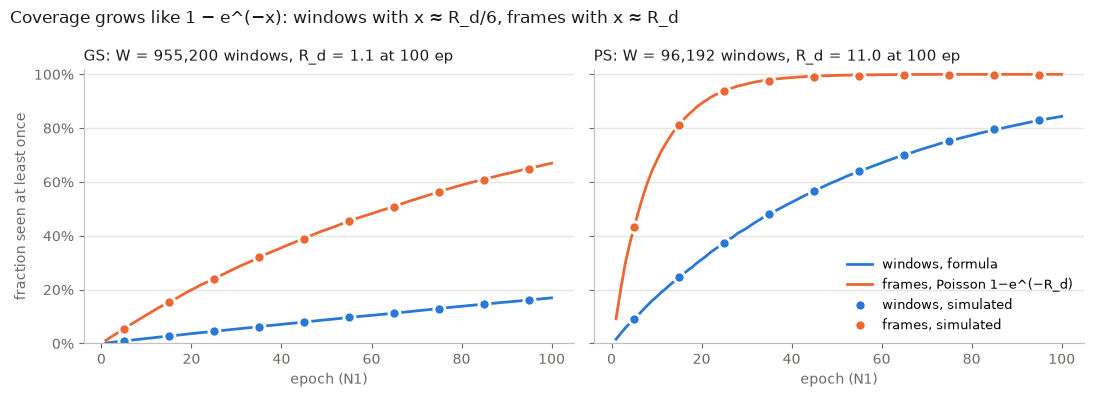

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2, as in notebook 4
INK, MUTED = "#1a1a19", "#6b6a64"

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor="white")
ep = np.array(EPOCHS)
for ax, n in zip(axes, sim):
    d = PRETRAIN_DATASETS.index(n)
    cum_windows = np.cumsum(draws[:, d]) * per_stream
    rd = cum_windows * T_IN * N_SP[n] / T_UNIQUE[n]
    win_formula = 1 - np.cumprod((1 - draws[:, d] / W[n]) ** per_stream)
    ax.plot(ep, win_formula, color=BLUE, lw=2, label="windows, formula")
    ax.plot(ep, 1 - np.exp(-rd), color=ORANGE, lw=2, label="frames, Poisson 1−e^(−R_d)")
    ax.plot(ep[4::10], sim[n][0][4::10], "o", ms=8, color=BLUE, mec="white", mew=2, label="windows, simulated")
    ax.plot(ep[4::10], sim[n][1][4::10], "o", ms=8, color=ORANGE, mec="white", mew=2, label="frames, simulated")
    ax.set_title(f"{CODE[n]}: W = {W[n]:,} windows, R_d = {rd[-1]:.1f} at 100 ep", color=INK, fontsize=11, loc="left")
    ax.set_xlabel("epoch (N1)", color=MUTED)
    ax.set_ylim(0, 1.02)
    ax.grid(axis="y", color="#e6e5e0", lw=1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("fraction seen at least once", color=MUTED)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[1].legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Coverage grows like 1 − e^(−x): windows with x ≈ R_d/6, frames with x ≈ R_d", x=0.01, ha="left", color=INK)
fig.tight_layout()
plt.show()

What to take away:

- The **window** formula matches the simulation exactly, so window coverage can be read off
  `R_d` (or better, off the replay) without simulating.
- The **frame** Poisson curve is a close approximation. The simulation sits a bit below it,
  because variable `dt` spreads a window's 6 input frames over up to 26 steps and late-trajectory
  windows are forced to `dt = 1` (§2.4), so exposure is not uniform.
- A repeated **window** is still not an identical sample. With `max_dt_stride = 5`, a window
  drawn twice usually gets a different `dt`, a different `RandomRotation90` and a different patch
  jitter. `R_d` counts it as a repeat, so it is an upper bound on how much "pure repetition" the
  model sees.

### 3.7 Fixed compute: what a FLOP budget buys each model shape

Until now the run length was fixed in epochs. For a scaling study the question is the other way
around: **given a compute budget `C` (FLOPs), how many tokens does a model of shape
`hidden/blocks/mlp` get to see, and how repeated does each dataset become?**

**FLOPs per micro-batch.** Notebook 4 derives these per stage. Here we just call the repo's
closed form:

- `well_registry.dataset_geometry(entry, kernel1, kernel2, T_in, B)` builds the `BatchGeometry` of
  one micro-batch of that dataset (padded encoder input, strides, channels, token grid), without
  loading data
- `flops.forward_flops(shape, geometry)` prices the forward pass
- `flops.training_step_flops(...)["useful"]` = forward × 3 (backward = 2× forward)

We use **useful** FLOPs, the `C ≈ 6ND` convention. Gradient checkpointing would add a recompute
surcharge (`training_step_flops(...)["recompute"]`), which costs wall time but buys no tokens.

FLOPs per micro-batch differ by dataset even though tokens barely do. The encoder has two cost
tiers (axes ≥ 512 get a 128-wide intermediate grid, smaller ones 66), and the channel count
matters too. So the mixture's cost per micro-batch is the **sampler-weighted mean**:

$$\bar f = \sum_d p_d\, f_d,\qquad \text{µbatches}(C) = \frac{C}{\bar f},\qquad \text{µbatches}_d = p_d\cdot\text{µbatches},\qquad R_d = \frac{\text{µbatches}_d\cdot B\, T_{in}\, N_{sp,d}}{T_{unique,d}}$$

with `p_d` from the 100-epoch replay (≈ 1/K). Equivalent epochs at N1 = µbatches / (`max_samples` · `ws`).

**The shape object.** `count_WALRUS_flops.model_shape(cfg)` builds the model on the meta device
(no memory, no weights) and reads a `ModelShape` off it with `ModelShape.from_model`, the same call
`FlopAccountant` makes in training. We do that once for fullDims and get the other shapes by
swapping the three knobs with `dataclasses.replace`. That is safe because the kernels,
`intermediate_dim` and `causal_in_time` belong to the fixed substrate. The cell checks this
against a fresh build of one other shape.

In [16]:
t0 = time.time()
base_shape, full_params, _ = cwf.model_shape(cfg)  # cfg = substrate + fullDims 1408/40/5632, no checkpointing
print(f"built in {time.time() - t0:.0f} s: {base_shape}  ({full_params / 1e9:.2f} B params)")

# Swapping only the shape knobs gives the same ModelShape as building that model for real.
cfg_anchor, _ = cwf.compose_config(SUBSTRATE + shape_overrides(768, 12, 2048, 0))
assert cwf.model_shape(cfg_anchor)[0] == replace(base_shape, hidden_dim=768, processor_blocks=12, mlp_dim=2048)

SHAPES = [  # (label, hidden_dim, processor_blocks, mlp_dim): SCALING_STRATEGY_2D.md's ladder, cheapest first
    ("Tier 2 smallest", 320, 6, 768),
    ("roofline small", 464, 10, 1120),
    ("Tier 2 largest", 560, 12, 1344),
    ("200 M anchor", 768, 12, 2048),
    ("SoWalrus pred.", 720, 24, 3616),
    ("HalfWalrus", 1088, 30, 4352),
    ("fullDims", 1408, 40, 5632),
]
p_d = np.array([replay[100][n] for n in PRETRAIN_DATASETS], dtype=float)
p_d /= p_d.sum()


def step_flops(h, L, m):
    # Useful training FLOPs of one micro-batch, per dataset.
    shape = replace(base_shape, hidden_dim=h, processor_blocks=L, mlp_dim=m)
    out = []
    for n in PRETRAIN_DATASETS:
        geom = wr.dataset_geometry(reg[n], shape.encoder_kernel1, shape.encoder_kernel2, T_IN, B)
        assert math.prod(geom.token_shape) == N_SP[n]
        out.append(training_step_flops(forward_flops(shape, geom), shape)["useful"])
    return np.array(out)


f_full = step_flops(1408, 40, 5632)
for n, f in zip(PRETRAIN_DATASETS, f_full):
    print(f"  fullDims {CODE[n]:6s}: {f / 1e12:6.2f} TFLOP / µbatch")

built in 0 s: ModelShape(hidden_dim=1408, mlp_dim=5632, processor_blocks=40, intermediate_dim=352, encoder_kernel1=(8, 8, 8), encoder_kernel2=(4, 4, 4), decoder_kernel1=(4, 4, 4), decoder_kernel2=(8, 8, 8), causal_in_time=True, gradient_checkpointing_freq=0, channel_mlp_dim=None)  (1.20 B params)


  fullDims AD    :  98.07 TFLOP / µbatch
  fullDims AI    :  98.07 TFLOP / µbatch
  fullDims AM    :  98.07 TFLOP / µbatch
  fullDims EMQ-O :  98.39 TFLOP / µbatch
  fullDims EMQ-P :  91.98 TFLOP / µbatch
  fullDims GS    :  91.70 TFLOP / µbatch
  fullDims PS    :  94.84 TFLOP / µbatch
  fullDims RB    :  94.89 TFLOP / µbatch
  fullDims SF    :  91.79 TFLOP / µbatch


The budget is one variable. By default it is what fullDims costs over 100 epochs on one node (the
replayed micro-batch counts times the per-dataset cost above). Change `C_BUDGET` and re-run the
next two cells to explore.

In [17]:
C_BUDGET = float(sum(replay[100][n] * f for n, f in zip(PRETRAIN_DATASETS, f_full)))  # FLOPs
print(f"C = {C_BUDGET:.3e} FLOPs  (fullDims × 100 epochs × N1)")

tok_d = np.array([B * T_IN * N_SP[n] for n in PRETRAIN_DATASETS])
tu_d = np.array([T_UNIQUE[n] for n in PRETRAIN_DATASETS])
w_d = np.array([W[n] for n in PRETRAIN_DATASETS])

rows, rd_rows = [], {}
for label, h, L, m in SHAPES:
    f_d = step_flops(h, L, m)
    f_bar = p_d @ f_d
    ub = C_BUDGET / f_bar                      # micro-batches over the whole job, all ranks
    ub_d = p_d * ub
    t_seen = ub_d @ tok_d
    rd = ub_d * tok_d / tu_d
    win_cov = 1 - np.exp(-ub_d * B / w_d)      # = 1 − (1 − r/W)^(n rank-epochs), r ≪ W
    rd_rows[f"{label}\n{h}/{L}/{m}"] = rd
    rows.append({
        "shape": f"{h}/{L}/{m}", "name": label,
        "TFLOP / µbatch": f_bar / 1e12,
        "epochs @ N1": ub / (MAX_SAMPLES * WS),
        "T_seen [G]": t_seen / 1e9,
        "R (aggregate)": t_seen / T_UNIQUE_MODEL,
        "R_d min (GS)": rd.min(), "R_d max (PS)": rd.max(),
        "window cov. GS": win_cov[PRETRAIN_DATASETS.index("gray_scott_reaction_diffusion")],
        "window cov. PS": win_cov[PRETRAIN_DATASETS.index("planetswe")],
    })
iso = pd.DataFrame(rows).set_index("shape")
assert abs(iso.loc["1408/40/5632", "epochs @ N1"] - 100) < 1e-6  # fullDims spends the budget in exactly 100 epochs
iso.style.format({"TFLOP / µbatch": "{:.2f}", "epochs @ N1": "{:,.0f}", "T_seen [G]": "{:,.1f}",
                  "R (aggregate)": "{:,.1f}", "R_d min (GS)": "{:,.1f}", "R_d max (PS)": "{:,.1f}",
                  "window cov. GS": "{:.1%}", "window cov. PS": "{:.1%}"})

C = 7.624e+19 FLOPs  (fullDims × 100 epochs × N1)


,name,TFLOP / µbatch,epochs @ N1,T_seen [G],R (aggregate),R_d min (GS),R_d max (PS),window cov. GS,window cov. PS
shape,,,,,,,,,
320/6/768,Tier 2 smallest,1.32,"7,196",732.2,224.6,79.7,795.1,100.0%,100.0%
464/10/1120,roofline small,3.26,"2,926",297.7,91.3,32.4,323.3,99.6%,100.0%
560/12/1344,Tier 2 largest,5.10,"1,868",190.1,58.3,20.7,206.4,96.9%,100.0%
768/12/2048,200 M anchor,8.84,"1,078",109.7,33.7,11.9,119.1,86.5%,100.0%
720/24/3616,SoWalrus pred.,18.38,519,52.8,16.2,5.7,57.3,61.8%,100.0%
1088/30/4352,HalfWalrus,44.39,215,21.8,6.7,2.4,23.7,32.9%,98.1%
1408/40/5632,fullDims,95.30,100,10.2,3.1,1.1,11.0,17.0%,84.3%


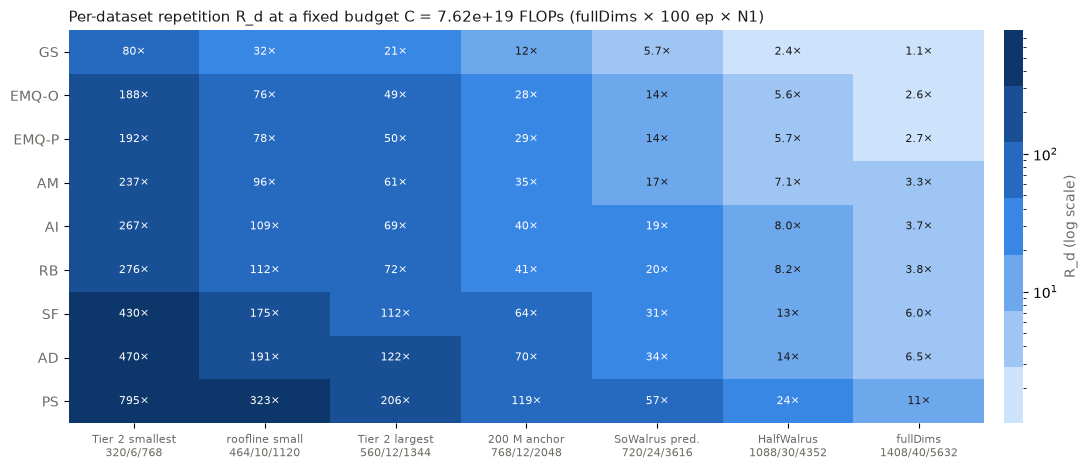

In [18]:
from matplotlib.colors import ListedColormap, LogNorm

# Sequential single-hue ramp (blue, light -> dark), log scale because R_d spans orders of magnitude.
BLUE_RAMP = ListedColormap(["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

order = np.argsort(-tu_d)  # largest dataset (least repeated) on top
mat = np.array(list(rd_rows.values())).T[order]
fig, ax = plt.subplots(figsize=(11, 4.8), facecolor="white")
im = ax.imshow(mat, cmap=BLUE_RAMP, norm=LogNorm(vmin=mat.min(), vmax=mat.max()), aspect="auto")
ax.set_xticks(range(len(rd_rows)), list(rd_rows), fontsize=8, color=MUTED)
ax.set_yticks(range(K), [CODE[PRETRAIN_DATASETS[i]] for i in order], color=MUTED)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat[i, j]
        dark = im.norm(v) * BLUE_RAMP.N >= 3  # white ink from the mid-blue step (#3987e5) up
        ax.text(j, i, f"{v:,.0f}×" if v >= 10 else f"{v:.1f}×", ha="center", va="center", fontsize=8,
                color="white" if dark else INK)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label("R_d (log scale)", color=MUTED)
cb.outline.set_visible(False)
ax.set_title(f"Per-dataset repetition R_d at a fixed budget C = {C_BUDGET:.2e} FLOPs (fullDims × 100 ep × N1)",
             loc="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

Reading the table and the heatmap:

- **At fixed compute, smaller models see many more tokens.** Processor FLOPs per token scale
  roughly like `L·H·(M + 4H)`, but the encoder/decoder and attention terms don't shrink with them.
  So the Tier 2 smallest shape is ~72× cheaper per micro-batch than fullDims, although the processor alone is
  ~110× cheaper: the encoder and decoder shrink only ~4×. For the same `C` it gets ≈ 7 200 equivalent epochs, and PS is
  repeated ≈ 790×.
- **Width and depth trade differently.** SoWalrus (720/24/3616) costs about twice the 200 M anchor
  (768/12/2048) per micro-batch despite being narrower, because it is twice as deep with a
  wider MLP. So it gets half the tokens and half the repetition.
- **Repetition is a data budget, not a compute one.** `R_d` depends only on tokens seen and the
  dataset's size. Any shape × duration with the same `T_seen` has the same `R_d` column. Fixed
  compute just maps shape to `T_seen`.
- **The spread between datasets stays 10×** (GS vs PS) at every shape, because uniform sampling
  gives every dataset the same token share regardless of size.
- **Coverage saturates long before `R_d` gets large.** At the small shapes every window of every
  dataset has been drawn, so extra tokens are purely repeated windows. At these budgets the only
  fresh variation left is `dt` / rotation / jitter augmentation.

### 3.8 Cheat sheet

| quantity | formula | repo function |
|---|---|---|
| frames `F_d` | `Σ_groups n_traj · n_steps` (train split) | `well_registry.n_frames(split)` |
| tokens per frame `N_sp` | `Π_axes (32 + [axis not periodic])` | `flops.analytic_token_shape`, `well_registry.token_shape` |
| unique tokens `T_unique,d` | `F_d · N_sp,d` | `well_registry.unique_model_tokens`, `flops.unique_model_tokens(datamodule)` |
| windows `W_d` = `len(dataset)` | `Σ n_traj · (n_steps − min_dt·(T_in+T_out−1))` | `well_registry.n_windows` → `raw_steps_to_possible_sample_t0s` |
| tokens / µbatch | `B · T_in · N_sp,d` | `count_WALRUS_flops` (`tokens_per_microbatch`) |
| tokens / opt step | tokens/µbatch · `ga` · `ws` | |
| tokens / epoch | tokens/µbatch · `max_samples` · `ws` | |
| µbatches of dataset `d` | `≈ max_samples · ws · E / K` (uniform over datasets) | exact: `count_WALRUS_flops.microbatch_counts` / `replay_epoch` |
| `T_seen,d` | µbatches_d · `B · T_in · N_sp,d` | W&B `tokens_seen` (aggregate) |
| repetition `R_d`, `R` | `T_seen,d / T_unique,d`, `Σ T_seen,d / T_unique_model` | W&B `repetition_factor` (aggregate) |
| epochs per full pass | `E` at which `R_d = 1` | |
| window coverage | `1 − Π_e (1 − r_{d,e}/W_d)^ws ≈ 1 − e^(−R_d·F_d/(W_d·T_in))` | (this notebook) |
| frame coverage | `≈ 1 − e^(−R_d)` (Poisson, `dt=1`) | (this notebook) |
| useful FLOPs / µbatch `f_d` | `3 × forward` | `flops.forward_flops` + `training_step_flops(...)["useful"]` on `well_registry.dataset_geometry` |
| µbatches for budget `C` | `C / Σ_d p_d f_d` | |